In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']

In [4]:
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc_hadcorr05.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and w<1')

In [5]:
print(max(df_allreco['nefs']))

0.8999996185302734


In [6]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

Process PYTHIA6+GEANT

In [7]:
df_match = applyCut(df_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')

In [8]:
print(df_match.shape[0], df_allfake.shape[0])

2663467 1505099


In [9]:
print(np.unique(df_match['bs']))

[-1  1]


In [10]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)],\
                       df_allreco[(df_allreco.pts>40) & (df_allreco.pts<60)]]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)] ]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]  ]

In [11]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [12]:
plt.rcParams['font.size'] = 12

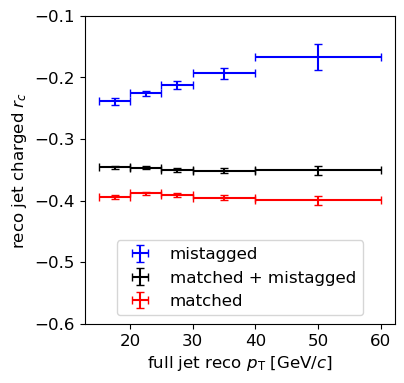

In [13]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')

In [14]:
rc_allfake_bs_vs_pts_array

[-0.23872883635450104,
 -0.22626199189628843,
 -0.21291545082209548,
 -0.19375984451281997,
 -0.16706183937170146]

In [15]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [16]:
b_fake_array = []
for i in range(0,5):
    df_fake_pts = df_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['ws'], density=True)
    b_fake_array.append(y_fake_rec/sum(y_fake_rec))

In [17]:
b_fake_array

[array([0.61936442, 0.38063558]),
 array([0.613131, 0.386869]),
 array([0.60645773, 0.39354227]),
 array([0.59687992, 0.40312008]),
 array([0.58353092, 0.41646908])]

In [18]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)]  ]

In [19]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

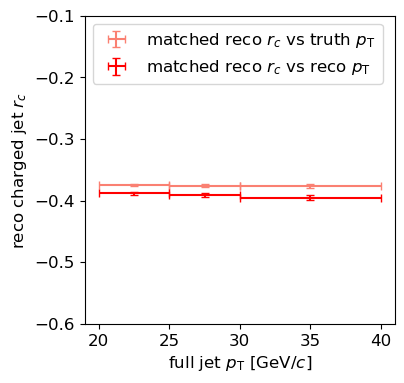

In [20]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='salmon', ls='none', label='matched reco $r_c$ vs truth $p_{\mathrm{T}}$')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched reco $r_c$ vs reco $p_{\mathrm{T}}$')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='upper left')

In [21]:
b_match_array = []
for i in range(0,5):
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['ws'], density=True)
    b_match_array.append(y_reco/sum(y_reco))
    print(y_reco/sum(y_reco))

[0.69695792 0.30304208]
[0.69400828 0.30599172]
[0.69547198 0.30452802]
[0.69758765 0.30241235]
[0.69990253 0.30009747]


In [22]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_600172/4101531506.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [23]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.30791222, 0.25663519, 0.23043332, 0.21646976, 0.20998295])

$r_c$ correction is not needed

In [24]:
rc_match_b_vs_pt_array = []
rc_err_match_b_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[0])
    rc_err_match_b_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'b')[1])

Text(20, -0.2, '$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

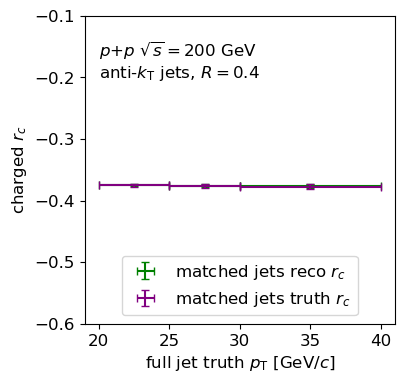

In [25]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='g', ls='none', label='matched jets reco $r_c$')
plt.errorbar([22.5, 27.5, 35], rc_match_b_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_b_vs_pt_array[1:-1], capsize=3, color='purple', ls='none', label='matched jets truth $r_c$')
plt.xlabel('full jet truth $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.2, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')
#plt.title('Matching cut: truth pT > 5 GeV, truth Nch > 2, reco Nch > 2, dR(truth,reco) < 0.02')

In [26]:
print(sum(df_match[(df_match.bs!=df_match.b)]['w'])/sum(df_match['w']))

0.0007859257915870397


In [27]:
print(sum(df_match[(df_match.bs!=df_match.b)&(df_match.pt>20)&(df_match.pts>15)]['w'])/sum(df_match[(df_match.pt>20)&(df_match.pts>15)]['w']))

0.0013753976822689573


In [28]:
print(rc_match_bs_vs_pt_array)
print(rc_match_b_vs_pt_array)

[-0.3892545835080884, -0.3749469251720575, -0.37570309329347396, -0.37639512591086227, -0.36523174541096143]
[-0.3896026205023962, -0.3755161404269639, -0.37637547388900316, -0.3772609978497856, -0.36718597724828494]


Process data

In [29]:
observables1 = ['pt','b']
file = uproot.open('/gpfs/gibbs/project/havener/ys668/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9 and bs!=0')

In [30]:
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [31]:
def getRcAndErrAndN(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [32]:
rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[1])

In [33]:
b_data_array = []
for i in range(0,5):
    df_data_pts = df_data_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_data_pts['bs'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
    b_data_array.append(y_reco)

# 1. Mistagged subtraction

In [34]:
def getMatchedCountAndErr(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [35]:
b_fakesubtracted_array = []
b_fakesubtractederr_array = []
rc1_array = []
rc1_err_array = []
for i in range(0,5):
    print(i)
    print(b_data_array[i])
    #print(getRc(data_array[i]))
    b_fakesubtracted, b_fakesubtractederr = getMatchedCountAndErr(b_data_array[i], fake_rate_array[i], b_fake_array[i])
    b_fakesubtracted_array.append(b_fakesubtracted)
    b_fakesubtractederr_array.append(b_fakesubtractederr)
    print(b_fakesubtracted)
    print(b_fakesubtractederr)
    nos = b_fakesubtracted[0]
    nss = b_fakesubtracted[1]
    n = nos + nss
    p = nss / n
    rc1 = (nss-nos) / (nss+nos)
    rc1_array.append(rc1)
    rc1_err_array.append( 2*np.sqrt(p*(1-p)/n) )

0
[337314. 178144.]
[239011.07151984 117731.11337173]
[488.88758577 343.11967791]
1
[72379. 38554.]
[54923.58268107 27540.10581082]
[234.35780909 165.95211903]
2
[16450.  8688.]
[12937.01315896  6408.3541581 ]
[113.74099155  80.05219646]
3
[4758. 2573.]
[3810.78748973 1933.27270052]
[61.73157612 43.96899704]
4
[334. 153.]
[274.32713859 110.41116559]
[16.56282399 10.50767175]


In [36]:
print(rc_data_bs_vs_pts_array)

[-0.3087933449476, -0.3049137767841851, -0.30877555891479036, -0.2980493793479744, -0.37166324435318276]


Text(20, -0.2, '$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

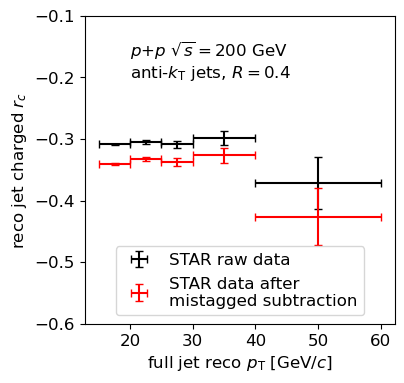

In [38]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_data_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_data_bs_vs_pts_array, capsize=3, color='k', ls='none', label='STAR raw data')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='STAR data after\nmistagged subtraction')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.2, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

# 2. $p_T$ correction

In [39]:
reweight_array = []
for i in range(0,5):
    reweight = (b_fakesubtracted_array[i]/sum(b_fakesubtracted_array[i]))/(b_match_array[i]/sum(b_match_array[i]))
    reweight_array.append(reweight)

In [40]:
reweight_array

[array([0.96129568, 1.08901496]),
 array([0.95969106, 1.09142319]),
 array([0.96156224, 1.087783  ]),
 array([0.95103602, 1.11294734]),
 array([1.01874569, 0.95628035])]

([], [])

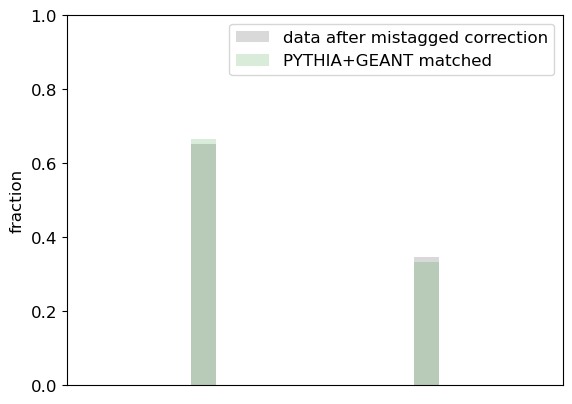

In [41]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=b_data_array[1]/sum(b_data_array[1]), color='k', alpha=0.15, label='data after mistagged correction')
plt.hist(x, weights=b_fakesubtracted_array[1]/sum(b_fakesubtracted_array[1]), ls='none', color='g', alpha=0.15, label='PYTHIA+GEANT matched')
#plt.errorbar(x+np.array([0.05,-0.05]), b_data_array[1][0]/sum(b_data_array[1]), yerr=y1err_array[0]/sum(b_data_array[1]), capsize=3, color='k', ls='none')
#plt.errorbar(x+np.array([0.05,-0.05]), b_fakesubtracted_array[1][0]/sum(b_fakesubtracted_array[1]), yerr=y1err_pythia_array[0]/sum(b_fakesubtracted_array[1]), capsize=3, color='g', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

Reweight PYTHIA6+GEANT

In [42]:
r = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pts'] > 15 and df_match.iloc[i]['pts'] < 20):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df_match.iloc[i]['pts'] > 20 and df_match.iloc[i]['pts'] < 25):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df_match.iloc[i]['pts'] > 25 and df_match.iloc[i]['pts'] < 30):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df_match.iloc[i]['pts'] > 30 and df_match.iloc[i]['pts'] < 40):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df_match.iloc[i]['pts'] > 40 and df_match.iloc[i]['pts'] < 60):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df_match.iloc[i]['pts'])
df_match['r'] = r #

anomaly reco pT: 68.96617247169604
anomaly reco pT: 60.153276062896694
anomaly reco pT: 62.853705443277754
anomaly reco pT: 62.96298659444578
anomaly reco pT: 60.83264616046272
anomaly reco pT: 60.31309896383466
anomaly reco pT: 60.91734178460715
anomaly reco pT: 60.481917097035925
anomaly reco pT: 66.103717780847
anomaly reco pT: 60.89421353610575
anomaly reco pT: 65.35667922469173
anomaly reco pT: 64.47875207921092
anomaly reco pT: 60.11131849040349
anomaly reco pT: 60.26115171262982
anomaly reco pT: 60.21434194892271
anomaly reco pT: 62.55584839791908
anomaly reco pT: 60.27780299483247
anomaly reco pT: 61.03197986884235
anomaly reco pT: 60.25483540234041
anomaly reco pT: 63.99508646678217
anomaly reco pT: 62.139164961369985
anomaly reco pT: 61.56890722000404
anomaly reco pT: 62.01326141868726
anomaly reco pT: 60.8697641572812
anomaly reco pT: 64.23631221912824
anomaly reco pT: 63.19369788337173
anomaly reco pT: 60.96653998630141
anomaly reco pT: 61.64508511587138
anomaly reco pT: 60

anomaly reco pT: 60.945626934831964
anomaly reco pT: 60.74067577434635
anomaly reco pT: 66.88495056985785
anomaly reco pT: 60.856769132346706
anomaly reco pT: 70.62264114647229
anomaly reco pT: 63.71397233021338
anomaly reco pT: 60.06181581868947
anomaly reco pT: 61.723594307211975
anomaly reco pT: 63.95246802002375
anomaly reco pT: 67.8581446933685
anomaly reco pT: 62.37163925475065
anomaly reco pT: 62.63471733037758
anomaly reco pT: 61.144115936189955
anomaly reco pT: 61.2110441827732
anomaly reco pT: 63.099376119447996
anomaly reco pT: 60.72284419784104
anomaly reco pT: 60.659634114539244
anomaly reco pT: 60.06686978750823
anomaly reco pT: 60.40795934028826
anomaly reco pT: 60.68433897369299
anomaly reco pT: 62.57750007093745
anomaly reco pT: 61.074198113150835
anomaly reco pT: 62.59641595524569
anomaly reco pT: 68.83628220142845
anomaly reco pT: 62.46624739393245
anomaly reco pT: 61.558573033106576
anomaly reco pT: 62.836733634710136
anomaly reco pT: 71.61772812163679
anomaly reco 

anomaly reco pT: 62.173479717802685
anomaly reco pT: 62.423084934365974
anomaly reco pT: 61.790378264427254
anomaly reco pT: 60.355440329212726
anomaly reco pT: 61.044594050012684
anomaly reco pT: 64.1822044337918
anomaly reco pT: 62.25934406797988
anomaly reco pT: 60.30630967921048
anomaly reco pT: 61.668104356262795
anomaly reco pT: 62.77769411151896
anomaly reco pT: 61.685289906527885
anomaly reco pT: 63.22484035674715
anomaly reco pT: 63.46598096489497
anomaly reco pT: 61.535248132418374
anomaly reco pT: 61.80732727157168
anomaly reco pT: 64.09907036344921
anomaly reco pT: 62.45406782900146
anomaly reco pT: 61.02351143590568
anomaly reco pT: 62.8217864166811
anomaly reco pT: 65.24180024811473
anomaly reco pT: 66.38162774159763
anomaly reco pT: 64.87767734017356
anomaly reco pT: 61.151999974483
anomaly reco pT: 60.863959217934024
anomaly reco pT: 64.2294299319846
anomaly reco pT: 62.47532122702217
anomaly reco pT: 60.076158415193916
anomaly reco pT: 61.13169963391717
anomaly reco pT

anomaly reco pT: 67.32893261745757
anomaly reco pT: 61.12696678470774
anomaly reco pT: 62.15602295447404
anomaly reco pT: 63.52619916634279
anomaly reco pT: 63.356786000286455
anomaly reco pT: 60.22452213521563
anomaly reco pT: 62.53457373412286
anomaly reco pT: 64.33333897786574
anomaly reco pT: 60.170790587436855
anomaly reco pT: 64.60139002565387
anomaly reco pT: 69.76020411425014
anomaly reco pT: 60.534238473134856
anomaly reco pT: 63.629621216145104
anomaly reco pT: 62.10724515878647
anomaly reco pT: 60.68828469625813
anomaly reco pT: 65.52781741653183
anomaly reco pT: 60.524631631539926
anomaly reco pT: 69.45049200670547
anomaly reco pT: 70.39201574361171
anomaly reco pT: 64.0105390313438
anomaly reco pT: 63.76803191155832
anomaly reco pT: 60.216702346192264
anomaly reco pT: 65.58352313403643
anomaly reco pT: 61.17962218807526
anomaly reco pT: 60.85774241109142
anomaly reco pT: 66.11044983586987
anomaly reco pT: 60.33344249231138
anomaly reco pT: 66.74378619614141
anomaly reco pT

anomaly reco pT: 61.55566986656164
anomaly reco pT: 63.77566253489699
anomaly reco pT: 60.41149473988145
anomaly reco pT: 64.16740787241898
anomaly reco pT: 71.71134063111128
anomaly reco pT: 61.653756039637734
anomaly reco pT: 60.19491352720952
anomaly reco pT: 60.719874837864914
anomaly reco pT: 63.323007001359706
anomaly reco pT: 62.39748345719461
anomaly reco pT: 65.47874514245692
anomaly reco pT: 60.39190902141452
anomaly reco pT: 65.0634806894151
anomaly reco pT: 65.86571741812644
anomaly reco pT: 62.174358337532375
anomaly reco pT: 61.25108554868977
anomaly reco pT: 61.947579640882736
anomaly reco pT: 60.64819671660582
anomaly reco pT: 63.46254812809013
anomaly reco pT: 62.96891790372958
anomaly reco pT: 61.46847161901648
anomaly reco pT: 65.74226558249495
anomaly reco pT: 64.48172194800236
anomaly reco pT: 61.5575326026705
anomaly reco pT: 62.4160863106184
anomaly reco pT: 63.2261305431496
anomaly reco pT: 61.77634558122546
anomaly reco pT: 60.86607307973257
anomaly reco pT: 60

anomaly reco pT: 64.77971349386596
anomaly reco pT: 61.78489382315072
anomaly reco pT: 60.04413809571338
anomaly reco pT: 60.792475845175815
anomaly reco pT: 62.52985186481692
anomaly reco pT: 67.9118087401383
anomaly reco pT: 61.67834935600106
anomaly reco pT: 60.27491085571325
anomaly reco pT: 60.76382153290241
anomaly reco pT: 60.181988155918255
anomaly reco pT: 60.02660310547757
anomaly reco pT: 63.30739533287466
anomaly reco pT: 64.85519208415829
anomaly reco pT: 64.27826399679385
anomaly reco pT: 66.92299480821671
anomaly reco pT: 60.42468380689887
anomaly reco pT: 62.95982715885367
anomaly reco pT: 66.26476521191687
anomaly reco pT: 63.50299654716414
anomaly reco pT: 60.236195885786024
anomaly reco pT: 62.26162049280147
anomaly reco pT: 65.33036863333659
anomaly reco pT: 66.20368934207268
anomaly reco pT: 65.69747893037193
anomaly reco pT: 62.25562933842256
anomaly reco pT: 66.29790763878857
anomaly reco pT: 68.49054309017268
anomaly reco pT: 62.65211374898822
anomaly reco pT: 6

... (58 outputs left out)

anomaly reco pT: 63.52486275561528
anomaly reco pT: 69.71762000778085
anomaly reco pT: 60.595525057374665
anomaly reco pT: 70.21183882786
anomaly reco pT: 61.862623728139084
anomaly reco pT: 69.23232730047685
anomaly reco pT: 63.69871317402888
anomaly reco pT: 60.227238154636986
anomaly reco pT: 60.199092480136365
anomaly reco pT: 65.45538811978611
anomaly reco pT: 61.29445689114465
anomaly reco pT: 64.60197789719952
anomaly reco pT: 63.29806084595935
anomaly reco pT: 61.38784203198595
anomaly reco pT: 61.461514111846114
anomaly reco pT: 65.0235397656114
anomaly reco pT: 64.03773850112078
anomaly reco pT: 62.74459880848217
anomaly reco pT: 62.15350058705068
anomaly reco pT: 60.59638530337815
anomaly reco pT: 63.785987733472304
anomaly reco pT: 60.44451750162317
anomaly reco pT: 64.66880986829807
anomaly reco pT: 66.1882805057379
anomaly reco pT: 62.818894033382016
anomaly reco pT: 66.70920254903149
anomaly reco pT: 62.08511636902384
anomaly reco pT: 60.395071038714676
anomaly reco pT: 

anomaly reco pT: 61.19651677313644
anomaly reco pT: 60.57189193972922
anomaly reco pT: 61.36140870644091
anomaly reco pT: 66.20092056844192
anomaly reco pT: 64.57576331775847
anomaly reco pT: 63.879728511310454
anomaly reco pT: 62.34042209197794
anomaly reco pT: 63.44889373555694
anomaly reco pT: 68.41403974868777
anomaly reco pT: 67.13701901699417
anomaly reco pT: 60.76169991150164
anomaly reco pT: 61.15688660921751
anomaly reco pT: 62.9823772250464
anomaly reco pT: 61.713797599168004
anomaly reco pT: 64.69412684679077
anomaly reco pT: 60.25964548017486
anomaly reco pT: 63.60931354818923
anomaly reco pT: 64.92874364207955
anomaly reco pT: 62.867720409034355
anomaly reco pT: 60.800711216141906
anomaly reco pT: 64.7109780489616
anomaly reco pT: 61.958724768245304
anomaly reco pT: 72.5918692440176
anomaly reco pT: 64.0143636951809
anomaly reco pT: 63.958705313210416
anomaly reco pT: 62.67429046435939
anomaly reco pT: 60.07445198834165
anomaly reco pT: 63.677781624252916
anomaly reco pT: 

anomaly reco pT: 60.117810075867474
anomaly reco pT: 60.921590501532116
anomaly reco pT: 73.34874109129544
anomaly reco pT: 65.75536078835533
anomaly reco pT: 71.46923522402538
anomaly reco pT: 66.39879311017162
anomaly reco pT: 60.98706622695438
anomaly reco pT: 60.04101815429556
anomaly reco pT: 60.21862550922213
anomaly reco pT: 68.36080273136002
anomaly reco pT: 61.52083599012493
anomaly reco pT: 61.91621515421579
anomaly reco pT: 61.178726833300146
anomaly reco pT: 61.04701030020529
anomaly reco pT: 60.070878682848516
anomaly reco pT: 67.86603476338651
anomaly reco pT: 60.65170514910797


/tmp/ipykernel_600172/3883675663.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match['r'] = r #


In [43]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    #variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        #variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [44]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)] ]
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)]  ]

In [45]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])
rc_match_bs_vs_pts_array_rw = []
rc_err_match_bs_vs_pts_array_rw = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[1])

Check that the reweighted embedding is the same as data

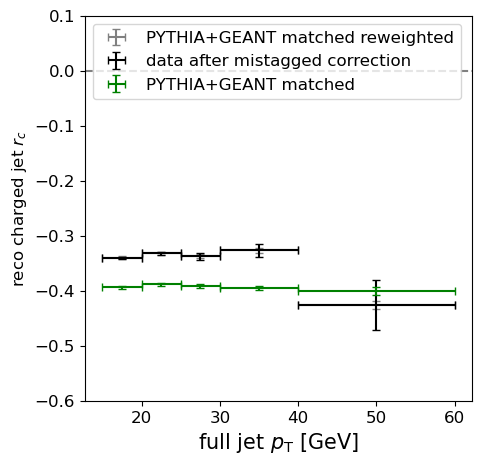

In [46]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array_rw, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array_rw, capsize=3, color='grey', ls='none', label='PYTHIA+GEANT matched reweighted')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='k', ls='none', label='data after mistagged correction')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='g', ls='none', label='PYTHIA+GEANT matched')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [47]:
print(rc_match_bs_vs_pts_array_rw)

[-0.339965283848077, -0.332067087602778, -0.3374791956108047, -0.32686196297225356, -0.42604536959004063]


Text(20, -0.25, 'STAR data\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

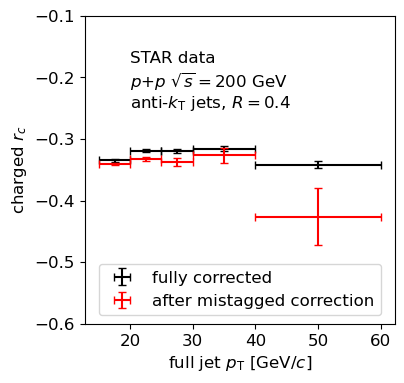

In [48]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='k', ls='none', label='fully corrected')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='after mistagged correction')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.25, 'STAR data\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

Plot result

(-0.6, 0.1)

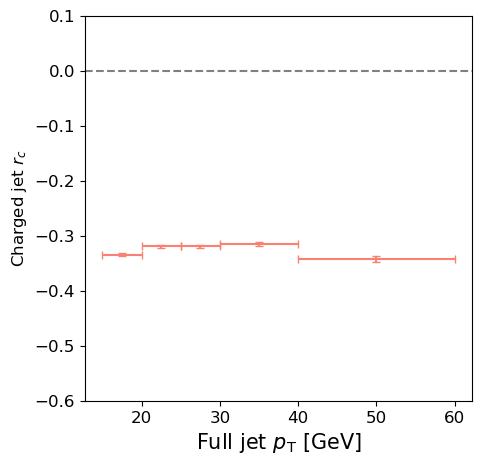

In [49]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='salmon', ls='none', label='sample 1 corrected')
#plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='sample 1 corrected')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.6,0.1)
#plt.legend(loc='upper left', fontsize=15)

In [50]:
rc_match_bs_vs_pt_array

[-0.3349242170613899,
 -0.3191809499731171,
 -0.3195074961463544,
 -0.3157538267478856,
 -0.34176464575385007]

In [51]:
rc_err_match_bs_vs_pt_array

[0.00283364274992657,
 0.0022566207281052154,
 0.0028190670253682307,
 0.0035074926423912483,
 0.005298338069611831]